# Kandy · CIFAKE baseline training

**Research question:** What fools an AI-image detector?

This notebook trains and documents the baseline CNN: the model definition, data preparation and split audit, training and resume code, the epoch report, learning curves and the official test evaluation. The trained weights are bundled inside the notebook, so no separate model download is needed.

**The analysis of the trained model now lives in the phase notebooks:**

| Notebook | Phase | Moved from this notebook |
| --- | --- | --- |
| `phase1/01_data_exploration.ipynb` | I | Section 4: training-data exploration |
| `phase1/02_cnn_training_and_visualization.ipynb` | I | Sections 10–11: sample predictions and the modification probe |
| `phase1/03_resnet18_finetuning_and_visualization.ipynb` | I | New: both models, sharpening and colour edits, classes, groups and agreement |
| `phase2/01_cnn_internals.ipynb` | II | Sections 12–13: Grad-CAM, contributions, occlusion, filters and channel removal |

**To use the trained model:** install the packages in Section 1, leave `MODE = "review"` in Section 2, and run the cells from top to bottom. Section 8 loads the included weights into `model`, ready for inference on CPU or GPU. The dataset is needed for full-data recalculation, training, or evaluation.

The completed plain CNN selected **epoch 19** by validation loss: **94.54% validation accuracy** and **94.29% official test accuracy**. Review mode reads the existing results and does not retrain or repeat test evaluation. To train a separate experiment, choose a new `RUN_NAME` and set `MODE = "train"`. Every completed epoch is checkpointed locally.

For the completed run, start with **section 6** for the epoch report and **section 11** for the summary. Implementation cells and saved data loaders are collapsed by default; expand them when you want to inspect the code.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = [
    "kagglehub==1.0.3",
    "torch==2.15.0",
    "numpy==2.5.4",
    "pillow==13.0.0",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "jupyterlab==4.6.5",
    "ipykernel==7.4.0",
    "nbformat==5.11.1",
    "nbclient==0.11.0",
    "plotly==7.1.0",
    "anywidget==0.11.0",
    "ipywidgets==8.1.9",
]

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")


Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

ROOT = Path.cwd().resolve()
NOTEBOOK_PATH = ROOT / "baseline_training.ipynb"
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib")
)

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)


def read_json(path):
    return json.loads(Path(path).read_text())


def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            "Save this notebook and set NOTEBOOK_PATH to its filename before training."
        )
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [
            s
            for s in shell.history_manager.input_hist_raw
            if s and "EMBEDDED_ASSETS =" not in s
        ]
        (source_dir / "executed_cells.txt").write_text(
            "\n\n# --- next executed cell ---\n\n".join(inputs)
        )


print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [3]:
# These assets travel inside the .ipynb, outside the visible code cells.
# They include the trained CNN, saved metrics and the figures used in review mode.
_NOTEBOOK_PAYLOADS = None


def notebook_payload(name):
    """Read the saved notebook once and retrieve one embedded data block."""
    global _NOTEBOOK_PAYLOADS
    if _NOTEBOOK_PAYLOADS is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                "Save this notebook and set NOTEBOOK_PATH to its filename before review."
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        _NOTEBOOK_PAYLOADS = saved_notebook["metadata"]["cifake"]
    return _NOTEBOOK_PAYLOADS[name]


# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = notebook_payload("baseline_assets")


def embedded_bytes(name):
    """Decode one bundled asset and check its checksum before using it."""
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw


for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print(
    "Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory."
)


Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


**The baseline architecture.** The model is a small CNN with two convolution-and-pooling stages and a 64-unit hidden layer. Its output is a REAL logit; converting it to a probability and applying the fixed threshold happens in the evaluation helpers.

In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        # Learn local patterns, then reduce their spatial size with max pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Combine the 32 feature maps into 64 hidden values and one REAL logit.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1)
        )
        # Initialize this small network from scratch; no pretrained weights are used.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


**Data integrity and predictions.** These helpers check the data, prepare batches and calculate metrics. File checksums keep the split consistent when the notebook is shared.

In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError(
            "MPS is unavailable in this process. Use an allowed GPU process or --device cpu."
        )
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (
        file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
        or actual["file_sha256"] != expected["file_sha256"]
    ):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset : offset + batch_size]
        x = (
            torch.from_numpy(images[idx])
            .to(device=device, dtype=torch.float32)
            .div_(255)
        )
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    """Run evaluation batches without updating the weights or tracking gradients."""
    model.eval()
    logits = [
        model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)
    ]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    """Summarize predictions with FAKE=0, REAL=1 and a fixed 0.5 threshold."""
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            [
                "path",
                "pixel_sha256",
                "label",
                "class_name",
                "logit_real",
                "p_real",
                "p_fake",
                "prediction",
                "correct",
            ]
        )
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow(
                [
                    row["path"],
                    row["pixel_sha256"],
                    row["label"],
                    row["class_name"],
                    float(logit),
                    float(probability),
                    float(1 - probability),
                    prediction,
                    prediction == row["class_name"],
                ]
            )


In [6]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError(
            "Identical pixels have conflicting labels; resolve before training."
        )
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "identical_to_official_test",
            )
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "repeated_training_image",
            )
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [
            i
            for i, r in enumerate(records)
            if r["split"] == "train" and r["label"] == label
        ]
        if len(eligible) <= validation_per_class:
            raise ValueError(
                "Not enough unique images for the requested validation size"
            )
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {
        s: {r["pixel_sha256"] for r in records if r["split"] == s}
        for s in ("train", "val", "test")
    }
    if (
        hashes["train"] & hashes["val"]
        or hashes["train"] & hashes["test"]
        or hashes["val"] & hashes["test"]
    ):
        raise AssertionError("Pixel overlap across splits")
    return records


def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    """Audit the images, assign the fixed splits and save arrays for training."""
    args = SimpleNamespace(
        data_root=Path(data_root),
        output=Path(output),
        seed=seed,
        validation_per_class=validation_per_class,
    )
    if args.output.exists():
        raise SystemExit(
            f"Refusing to overwrite {args.output}; reuse it or choose a new --output."
        )
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(
                    f"{source}/{class_name}: expected {expected}, found {len(paths)}"
                )
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append(
                    {
                        "path": path.relative_to(args.data_root).as_posix(),
                        "source_split": source,
                        "class_name": class_name,
                        "label": label,
                        "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest(),
                    }
                )
            print(
                f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True
            )
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = [
        "path",
        "source_split",
        "class_name",
        "label",
        "pixel_sha256",
        "split",
        "exclusion_reason",
    ]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(
            args.output / f"{split}_images.npy", np.stack([images[i] for i in indices])
        )
        np.save(
            args.output / f"{split}_labels.npy",
            np.array([records[i]["label"] for i in indices], dtype=np.int64),
        )
    counts = {
        s: dict(Counter(r["class_name"] for r in records if r["split"] == s))
        for s in ("train", "val", "test", "excluded")
    }
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed,
        "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()),
        "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(
            Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")
        ),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes),
        "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {
            p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()
        },
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(
        f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}",
        flush=True,
    )
    print(f"Prepared data: {args.output}", flush=True)


**Saving and restoring training.** Checkpoint writes replace a file only after the new save completes. Recovery checks the existing configuration, data and history before restoring optimizer and random states.

In [7]:
def save_checkpoint(path, state):
    """Keep the previous checkpoint intact until the new save is complete."""
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as handle:
        torch.save(state, handle)
        handle.flush()
        os.fsync(handle.fileno())
    temporary.replace(path)


def read_resume(args):
    """Restore a compatible run and check that its data and history still match."""
    if (args.output / "test_metrics.json").exists():
        raise SystemExit(
            "This baseline has already been test-evaluated. Preserve it; use a separate run for new experiments."
        )
    config = json.loads((args.output / "config.json").read_text())
    status_path = args.output / "status.json"
    if status_path.exists():
        status = json.loads(status_path.read_text())
        if status.get("status") == "running":
            try:
                os.kill(status["pid"], 0)
            except ProcessLookupError:
                pass
            else:
                raise SystemExit(f"Training process {status['pid']} is still active")
    checkpoint = torch.load(
        args.output / "last.pt", map_location="cpu", weights_only=True
    )
    for key in ("seed", "batch_size", "learning_rate", "patience", "min_delta"):
        requested = getattr(args, key)
        if requested is not None and requested != config[key]:
            raise SystemExit(
                f"Cannot change --{key.replace('_', '-')} when resuming an existing experiment"
            )
        setattr(args, key, config[key])
    args.epochs = args.epochs if args.epochs is not None else config["epochs"]
    if args.epochs < checkpoint["epoch"]:
        raise SystemExit("Requested epoch limit is earlier than the saved checkpoint")
    if args.data_dir is None:
        original = Path(config["data_dir"])
        args.data_dir = original if original.exists() else Path("data/baseline_seed1")
    verify_run_data(args.data_dir, args.output, config)
    with (args.output / "history.csv").open(newline="") as handle:
        history = [
            {k: int(v) if k == "epoch" else float(v) for k, v in row.items()}
            for row in csv.DictReader(handle)
            if int(row["epoch"]) <= checkpoint["epoch"]
        ]
    if [r["epoch"] for r in history] != list(range(1, checkpoint["epoch"] + 1)):
        raise ValueError("History is incomplete for the saved checkpoint")
    # The epoch file is written before last.pt, so this also repairs a best.pt
    # update interrupted between those atomic saves.
    best_file = args.output / "checkpoints" / f"epoch_{checkpoint['best_epoch']:03d}.pt"
    best = torch.load(best_file, map_location="cpu", weights_only=True)
    save_checkpoint(args.output / "best.pt", best)
    return checkpoint, config, history


**Training the CNN.** This function handles the complete training run. Its comments mark batch updates, validation, checkpoint selection and early stopping. It is only called when the configuration explicitly requests training or recovery.

In [8]:
def train_model(
    data_dir=None,
    output="runs/baseline_plain_seed1",
    device="auto",
    seed=None,
    epochs=None,
    batch_size=None,
    learning_rate=None,
    patience=None,
    min_delta=None,
    resume=False,
):
    args = SimpleNamespace(
        data_dir=Path(data_dir) if data_dir is not None else None,
        output=Path(output),
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=batch_size,
        learning_rate=learning_rate,
        patience=patience,
        min_delta=min_delta,
        resume=resume,
    )
    resume, original_config, history = None, None, []
    if args.resume:
        resume, original_config, history = read_resume(args)
    else:
        if args.output.exists():
            raise SystemExit(
                f"Refusing to overwrite {args.output}; use --resume or choose a new --output."
            )
        defaults = {
            "data_dir": Path("data/baseline_seed1"),
            "seed": 1,
            "epochs": 30,
            "batch_size": 128,
            "learning_rate": 0.001,
            "patience": 5,
            "min_delta": 0.0001,
        }
        for key, value in defaults.items():
            if getattr(args, key) is None:
                setattr(args, key, value)
    if (
        min(args.epochs, args.batch_size, args.patience) < 1
        or args.learning_rate <= 0
        or args.min_delta < 0
    ):
        raise SystemExit("Invalid training parameters")
    device = choose_device(args.device)
    torch.set_num_threads(4)
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    rng = np.random.default_rng(args.seed)

    # Only training and validation data enter training; test images stay out of model selection.
    train_images, train_labels, _ = load_split(args.data_dir, "train")
    val_images, val_labels, val_rows = load_split(args.data_dir, "val")
    model = BaselineCNN().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=args.learning_rate, weight_decay=0
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-5
    )
    criterion = nn.BCEWithLogitsLoss()
    args.output.mkdir(parents=True, exist_ok=args.resume)
    (args.output / "checkpoints").mkdir(exist_ok=args.resume)
    source_dir = args.output / (
        f"source_resume_{time.time_ns()}" if args.resume else "source"
    )
    source_dir.mkdir()
    snapshot_notebook(source_dir)
    log = logging.getLogger("cifake.training")
    log.setLevel(logging.INFO)
    log.propagate = False
    for handler in list(log.handlers):
        handler.close()
        log.removeHandler(handler)
    # Send progress to the notebook output and to a persistent training.log file.
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(args.output / "training.log"),
    ):
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        log.addHandler(handler)
    config = {
        **{k: str(v) if isinstance(v, Path) else v for k, v in vars(args).items()},
        "data_dir": str(args.data_dir.resolve()),
        "device_used": str(device),
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "architecture": "Conv(3,32,3)-ReLU-Pool(2)-Conv(32,32,3)-ReLU-Pool(2)-Flatten-Linear(1152,64)-ReLU-Linear(64,1)",
        "parameters": sum(p.numel() for p in model.parameters()),
        "class_to_index": LABELS,
        "preprocessing": "native RGB 32x32; float32 / 255",
        "augmentation": None,
        "optimizer": "Adam, weight_decay=0",
        "loss": "BCEWithLogitsLoss; logits represent REAL",
        "scheduler": "ReduceLROnPlateau(validation_loss, factor=0.5, patience=2, min_lr=1e-5)",
        "checkpoint_selection": "Lowest validation BCE; fixed 0.5 probability threshold",
        "test_usage": "Not loaded by this program; evaluate only after model selection is complete",
        "paper": "https://arxiv.org/html/2303.14126v1",
        "reproduction_note": "Paper-inspired architecture, not an exact reproduction. Split, optimizer, initialization, kernel/pooling implementation, scheduler, and early stopping are explicitly specified for this experiment.",
        "determinism": "Seeded Python, NumPy and Torch; deterministic algorithms requested with warn_only. Bitwise identity across hardware/software is not guaranteed.",
        "manifest_sha256": file_sha256(args.data_dir / "manifest.csv"),
        "audit_sha256": file_sha256(args.data_dir / "audit.json"),
        "source_sha256": {p.name: file_sha256(p) for p in source_dir.iterdir()},
        "environment": {
            "python": sys.version,
            "platform": platform.platform(),
            "packages": {
                d.metadata["Name"]: d.version
                for d in importlib.metadata.distributions()
            },
        },
    }
    if resume is not None:
        invocation = {
            "resumed_utc": config["started_utc"],
            "from_epoch": resume["epoch"],
            "device": str(device),
            "source_directory": source_dir.name,
            "source_sha256": config["source_sha256"],
            "environment": config["environment"],
        }
        config = {
            **original_config,
            "data_dir": str(args.data_dir.resolve()),
            "epochs": args.epochs,
            "resumes": original_config.get("resumes", []) + [invocation],
        }
    write_json(args.output / "config.json", config)
    if not args.resume:
        shutil.copy2(args.data_dir / "audit.json", args.output / "data_audit.json")
    write_json(
        args.output / "status.json",
        {
            "status": "running",
            "pid": os.getpid(),
            "epoch": resume["epoch"] if resume else 0,
        },
    )
    log.info(
        "Device=%s; parameters=%s; train=%s; validation=%s; no augmentation",
        device,
        config["parameters"],
        len(train_labels),
        len(val_labels),
    )
    best_loss, early_stop_best, best_epoch, stale_epochs = (
        float("inf"),
        float("inf"),
        0,
        0,
    )
    start_epoch = 1
    if resume is not None:
        model.load_state_dict(resume["model_state_dict"])
        optimizer.load_state_dict(resume["optimizer_state_dict"])
        scheduler.load_state_dict(resume["scheduler_state_dict"])
        rng.bit_generator.state = resume["numpy_generator_state"]
        torch.set_rng_state(resume["torch_rng_state"].cpu())
        if "python_rng_state" in resume:
            random.setstate(resume["python_rng_state"])
        if "numpy_legacy_rng_state" in resume:
            legacy = resume["numpy_legacy_rng_state"]
            np.random.set_state(
                (legacy[0], np.array(legacy[1], dtype=np.uint32), *legacy[2:])
            )
        previous_device = original_config.get("resumes", [{}])[-1].get(
            "device", original_config["device_used"]
        )
        if resume.get("accelerator_rng_state") is not None and previous_device == str(
            device
        ):
            if device.type == "mps":
                torch.mps.set_rng_state(resume["accelerator_rng_state"].cpu())
            elif device.type == "cuda":
                torch.cuda.set_rng_state(resume["accelerator_rng_state"].cpu())
        best_loss, best_epoch, stale_epochs = (
            resume["best_val_loss"],
            resume["best_epoch"],
            resume["stale_epochs"],
        )
        for row in history:
            if row["val_loss"] < early_stop_best - args.min_delta:
                early_stop_best = row["val_loss"]
        start_epoch = resume["epoch"] + 1
        log.info(
            "Restored checkpoint at epoch %s, including optimizer, scheduler, and RNG state",
            resume["epoch"],
        )
        if stale_epochs >= args.patience:
            log.info(
                "Early stopping already reached; restoring final reports without additional training"
            )
            start_epoch = args.epochs + 1
    started = time.perf_counter()
    prior_epoch_seconds = sum(row["seconds"] for row in history)
    fields = [
        "epoch",
        "train_loss",
        "train_accuracy",
        "val_loss",
        "val_accuracy",
        "val_roc_auc_fake",
        "learning_rate",
        "seconds",
    ]
    try:
        with (args.output / "history.csv").open("w", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=fields)
            writer.writeheader()
            writer.writerows(history)
            handle.flush()
            for epoch in range(start_epoch, args.epochs + 1):
                epoch_started = time.perf_counter()
                lr = optimizer.param_groups[0]["lr"]
                # Enable training mode for this epoch and reset the running totals.
                model.train()
                total_loss = torch.zeros((), device=device)
                total_correct = torch.zeros((), device=device)
                for x, y in batches(
                    train_images,
                    train_labels,
                    args.batch_size,
                    device,
                    rng.permutation(len(train_labels)),
                ):
                    # Predict this batch, measure its error, and update the weights using its gradients.
                    optimizer.zero_grad(set_to_none=True)
                    logits = model(x)
                    loss = criterion(logits, y)
                    if not torch.isfinite(loss).item():
                        raise RuntimeError("Non-finite training loss")
                    loss.backward()
                    optimizer.step()
                    total_loss += loss.detach() * len(y)
                    total_correct += ((logits.detach() >= 0) == y.bool()).sum()
                # Evaluate the entire validation split without changing the weights.
                val_logits = predict(
                    model, val_images, val_labels, args.batch_size, device
                )
                metrics = classification_metrics(val_labels, val_logits)
                scheduler.step(metrics["loss"])
                row = {
                    "epoch": epoch,
                    "train_loss": total_loss.item() / len(train_labels),
                    "train_accuracy": total_correct.item() / len(train_labels),
                    "val_loss": metrics["loss"],
                    "val_accuracy": metrics["accuracy"],
                    "val_roc_auc_fake": metrics["roc_auc_fake"],
                    "learning_rate": lr,
                    "seconds": time.perf_counter() - epoch_started,
                }
                writer.writerow(row)
                handle.flush()
                history.append(row)
                # Select by validation loss; a higher accuracy alone does not replace the best checkpoint.
                improved = metrics["loss"] < best_loss
                if improved:
                    best_loss, best_epoch = metrics["loss"], epoch
                if metrics["loss"] < early_stop_best - args.min_delta:
                    early_stop_best, stale_epochs = metrics["loss"], 0
                else:
                    stale_epochs += 1
                # Save optimizer, scheduler and random states so recovery continues the same experiment.
                checkpoint = {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "validation_metrics": metrics,
                    "best_epoch": best_epoch,
                    "best_val_loss": best_loss,
                    "stale_epochs": stale_epochs,
                    "numpy_generator_state": rng.bit_generator.state,
                    "early_stop_best": early_stop_best,
                    "python_rng_state": random.getstate(),
                    "numpy_legacy_rng_state": [
                        np.random.get_state()[0],
                        np.random.get_state()[1].tolist(),
                        *np.random.get_state()[2:],
                    ],
                    "torch_rng_state": torch.get_rng_state(),
                    "accelerator_rng_state": (
                        torch.mps.get_rng_state()
                        if device.type == "mps"
                        else (
                            torch.cuda.get_rng_state()
                            if device.type == "cuda"
                            else None
                        )
                    ),
                    "config": config,
                }
                save_checkpoint(
                    args.output / "checkpoints" / f"epoch_{epoch:03d}.pt", checkpoint
                )
                save_checkpoint(args.output / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(args.output / "best.pt", checkpoint)
                write_json(
                    args.output / "status.json",
                    {
                        "status": "running",
                        "pid": os.getpid(),
                        "epoch": epoch,
                        "best_epoch": best_epoch,
                        "best_val_loss": best_loss,
                        "last_epoch": row,
                    },
                )
                log.info(
                    "Epoch %02d/%02d | train loss %.4f acc %.2f%% | val loss %.4f acc %.2f%% | lr %.5f | %.1fs%s",
                    epoch,
                    args.epochs,
                    row["train_loss"],
                    100 * row["train_accuracy"],
                    row["val_loss"],
                    100 * row["val_accuracy"],
                    lr,
                    row["seconds"],
                    " | best" if improved else "",
                )
                if stale_epochs >= args.patience:
                    log.info(
                        "Early stopping after %s epochs without sufficient validation-loss improvement",
                        args.patience,
                    )
                    break
        # Restore the selected epoch before producing the final validation report.
        best = torch.load(
            args.output / "best.pt", map_location=device, weights_only=True
        )
        model.load_state_dict(best["model_state_dict"])
        logits = predict(model, val_images, val_labels, args.batch_size, device)
        validation = classification_metrics(val_labels, logits)
        save_predictions(args.output / "validation_predictions.csv", val_rows, logits)
        write_json(args.output / "validation_metrics.json", validation)
        summary = {
            "status": "completed",
            "best_epoch": best_epoch,
            "epochs_run": len(history),
            "elapsed_seconds": prior_epoch_seconds + time.perf_counter() - started,
            "validation": validation,
            "stop_reason": (
                "early_stopping" if stale_epochs >= args.patience else "max_epochs"
            ),
            "test_evaluated": False,
            "best_checkpoint": "best.pt",
        }
        write_json(args.output / "summary.json", summary)
        write_json(args.output / "status.json", summary)
        log.info(
            "Complete. Selected epoch %s by validation loss. Test set has not been evaluated.",
            best_epoch,
        )
    except BaseException as exc:
        write_json(
            args.output / "status.json",
            {
                "status": (
                    "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed"
                ),
                "error": str(exc),
                "completed_epochs": len(history),
            },
        )
        raise


In [9]:
def evaluate_model(run_dir, data_dir=None, device="auto"):
    args = SimpleNamespace(
        run_dir=Path(run_dir),
        data_dir=Path(data_dir) if data_dir is not None else None,
        device=device,
    )
    summary = json.loads((args.run_dir / "summary.json").read_text())
    if summary["status"] != "completed":
        raise SystemExit("Training must finish before test evaluation")
    if (args.run_dir / "test_metrics.json").exists():
        raise SystemExit(
            "Test already evaluated; read test_metrics.json instead of using it to tune the model."
        )
    config = json.loads((args.run_dir / "config.json").read_text())
    data_dir = args.data_dir or Path(config["data_dir"])
    if args.data_dir is None and not data_dir.exists():
        data_dir = Path("data/baseline_seed1")
    verify_run_data(data_dir, args.run_dir, config)
    device = choose_device(args.device)
    torch.set_num_threads(4)
    model = BaselineCNN().to(device)
    checkpoint = torch.load(
        args.run_dir / "best.pt", map_location=device, weights_only=True
    )
    if checkpoint["epoch"] != summary["best_epoch"]:
        raise ValueError("Checkpoint does not match selected epoch")
    model.load_state_dict(checkpoint["model_state_dict"])
    images, labels, rows = load_split(data_dir, "test")
    logits = predict(model, images, labels, config["batch_size"], device)
    metrics = classification_metrics(labels, logits)
    # Preserve the official benchmark, and also report each unique test image once.
    seen, unique_indices = set(), []
    for idx, row in enumerate(rows):
        if row["pixel_sha256"] not in seen:
            unique_indices.append(idx)
            seen.add(row["pixel_sha256"])
    indices = np.array(unique_indices)
    result = {
        "selected_epoch": checkpoint["epoch"],
        "checkpoint_sha256": file_sha256(args.run_dir / "best.pt"),
        "official_test": metrics,
        "unique_test": classification_metrics(labels[indices], logits[indices]),
        "note": "Fixed threshold 0.5. No test-driven tuning. Clean CIFAKE performance only, not robustness or unseen-generator performance.",
    }
    save_predictions(args.run_dir / "test_predictions.csv", rows, logits)
    write_json(args.run_dir / "test_metrics.json", result)
    summary["test_evaluated"] = True
    summary["test_metrics"] = "test_metrics.json"
    write_json(args.run_dir / "summary.json", summary)
    write_json(args.run_dir / "status.json", summary)
    print(json.dumps(result, indent=2))


## 2. Experiment configuration

- `review`: inspect the existing run; no training or new test evaluation.
- `train`: start a new run. Choose an unused `RUN_NAME`; existing runs are never overwritten.
- `resume`: continue the named run from its last complete checkpoint. The original hyperparameters and stopping rule are restored. A test-evaluated run stays fixed.

`SPLIT_SEED` controls membership of the train/validation split. Keep this fixed for model comparisons; `TRAINING['seed']` controls model initialization and shuffling. The pipeline has no flips, crops, blur, noise, or JPEG augmentation.

In [10]:
# Keep review mode to inspect the saved experiment. Use a new run name for a new training experiment.
MODE = "review"  # "review", "train", or "resume"
RUN_NAME = "baseline_plain_seed1"  # Use a NEW name to train another model.
DEVICE = "auto"  # "auto", "mps", "cuda", or "cpu"

SAVE_FIGURES = False  # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False
EVALUATE_TEST = False  # Enable only after training/model selection is complete.
EXPORT_RUN = False  # Optional local full-checkpoint archive.

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None


def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)


show_table(
    ["Setting", "Value"],
    [
        ("Mode", MODE),
        ("Run", RUN_NAME),
        ("Device", str(device)),
        ("Augmentation", "None"),
        *TRAINING.items(),
    ],
)

| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Data and a split without exact duplicate leakage

CIFAKE's official split has 100,000 development images and 20,000 test images. We preserve all official test images, exclude development images with identical test pixels, keep one copy of each remaining development image, and reserve 5,000 images of each label for validation.

| Split | FAKE | REAL | Total |
| --- | ---: | ---: | ---: |
| Training | 43,702 | 45,000 | 88,702 |
| Validation | 5,000 | 5,000 | 10,000 |
| Official test | 10,000 | 10,000 | 20,000 |

The audit excluded **378 test overlaps** and **920 repeated training copies**, all FAKE. Hashes are calculated from decoded RGB pixels, not filenames. The test set contains 38 repeated copies, so we also report metrics on its 19,962 unique images. Near-duplicates have not been screened. Stratification uses REAL/FAKE; semantic classes are not inferred from filenames.

The next cell only downloads or prepares data when the corresponding configuration flag is enabled. Existing prepared data is reused.

In [11]:
if DOWNLOAD_DATA:
    os.environ.setdefault("KAGGLEHUB_CACHE", str(ROOT / "data" / ".kagglehub"))
    import kagglehub

    kagglehub.dataset_download(
        "birdy654/cifake-real-and-ai-generated-synthetic-images",
        output_dir=str(RAW_DATA),
    )

if PREPARE_DATA and not (DATA_DIR / "audit.json").exists():
    prepare_data(
        RAW_DATA, DATA_DIR, seed=SPLIT_SEED, validation_per_class=VALIDATION_PER_CLASS
    )

if (DATA_DIR / "audit.json").exists():
    audit = read_json(DATA_DIR / "audit.json")
    if (
        audit["seed"] != SPLIT_SEED
        or audit["validation_per_class"] != VALIDATION_PER_CLASS
    ):
        raise ValueError(
            "Prepared split settings differ. Reuse its settings or choose a new DATA_DIR."
        )
    print("Using the existing prepared split.")
else:
    audit = read_result("data_audit.json")
    print(
        "Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train."
    )

if audit:
    show_table(
        ["Split", "FAKE", "REAL", "Total"],
        [
            [split, counts.get("FAKE", 0), counts.get("REAL", 0), sum(counts.values())]
            for split, counts in audit["split_counts"].items()
        ],
    )
    print("Exclusions:", audit["exclusion_counts"])
    print(
        "Exact pixel overlap across splits:", audit["exact_pixel_overlap_across_splits"]
    )


Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train.


| Split | FAKE | REAL | Total |
| --- | --- | --- | --- |
| train | 43702 | 45000 | 88702 |
| val | 5000 | 5000 | 10000 |
| test | 10000 | 10000 | 20000 |
| excluded | 1298 | 0 | 1298 |

Exclusions: {'identical_to_official_test': 378, 'repeated_training_image': 920}
Exact pixel overlap across splits: 0


In [12]:
# Recheck split membership when the local manifest is available. This reads metadata, not model outputs.
manifest_path = DATA_DIR / "manifest.csv"
if manifest_path.exists():
    assert file_sha256(manifest_path) == audit["file_sha256"]["manifest.csv"]
    manifest = read_csv(manifest_path)
    split_hashes = {
        split: {row["pixel_sha256"] for row in manifest if row["split"] == split}
        for split in ("train", "val", "test")
    }
    assert not (split_hashes["train"] & split_hashes["val"])
    assert not (split_hashes["train"] & split_hashes["test"])
    assert not (split_hashes["val"] & split_hashes["test"])
    assert len(split_hashes["train"]) == sum(audit["split_counts"]["train"].values())
    assert len(split_hashes["val"]) == 2 * VALIDATION_PER_CLASS
    print(
        "Verified: no exact duplicate leakage, and unique training/validation images."
    )
    del manifest, split_hashes
else:
    print(
        "Live membership check skipped: the saved audit is available, but this clone has no local manifest."
    )


Live membership check skipped: the saved audit is available, but this clone has no local manifest.


## 4. The baseline network

The architecture follows the small-CNN direction in [the CIFAKE paper, Section 4.2 and Figure 5](https://arxiv.org/html/2303.14126v1): two convolutional layers with 32 filters and a 64-unit dense layer. Our kernel/pooling choices, split, Adam optimizer, and stopping settings are documented implementation choices, so this is **paper-inspired**, not an exact reproduction.

`32×32 RGB → Conv(32) → ReLU → MaxPool → Conv(32) → ReLU → MaxPool → Flatten → Dense(64) → ReLU → 1 logit`

There are **84,001 trainable parameters**. Preprocessing is only `float32 / 255`. There is no pretraining, dropout, batch normalization, weight decay, or augmentation. `FAKE=0`, `REAL=1`; the sigmoid of the output is **P(REAL)**. Training uses `BCEWithLogitsLoss`, which includes the sigmoid internally.

The model class is defined in the notebook implementation above. The next cell displays its layers and checks its parameter count.

In [13]:
architecture_preview = BaselineCNN()
print(architecture_preview)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in architecture_preview.parameters()):,}",
)
print("Label mapping:", LABELS)
del architecture_preview


BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 84,001
Label mapping: {'FAKE': 0, 'REAL': 1}


## 5. Training and automatic checkpoints

Training uses Adam with the settings above. The learning rate is halved after a validation-loss plateau; early stopping triggers after five epochs without an improvement of at least 0.0001. The checkpoint with the **lowest validation BCE**, rather than the highest accuracy, is selected.

Every completed epoch saves model weights, optimizer, scheduler, random states, and metrics. `last.pt` is the recovery point; `best.pt` is the validation-selected model. Saves use a temporary file and atomic replacement. Interrupting the kernel can lose the unfinished epoch; completed epochs stay on disk.

The cell calls `train_model`, defined entirely in this notebook. A copy of the notebook and executed-code history is saved with each new run. Progress is printed here and written to `training.log`. Training never loads test images. In `review` mode, the cell reads the existing result.

In [14]:
if MODE == "train":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, **TRAINING)
elif MODE == "resume":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, resume=True)
else:
    print("Review mode: loading saved training results; no new training was run.")

run_summary = read_result("summary.json")
if run_summary:
    selected_epoch = run_summary.get("best_epoch", run_summary.get("selected_epoch"))
    print(
        f"Completed epochs: {run_summary['epochs_run']} | Selected epoch: {selected_epoch}"
    )
    print(
        f"Validation accuracy of selected model: {run_summary['validation']['accuracy']:.2%}"
    )
else:
    selected_epoch = None
    print("No completed result for this run yet.")


Review mode: loading saved training results; no new training was run.
Completed epochs: 24 | Selected epoch: 19
Validation accuracy of selected model: 94.54%


## 6. Training report and checkpoint recovery

The table below is the saved record of the completed run. Each row is one full pass through the training images, followed by evaluation on the untouched validation split. We show the training and validation loss, both accuracies, the learning rate used during that epoch and its duration. The selected row is the lowest validation loss, which is not necessarily the row with the highest validation accuracy. The learning rate falls when validation loss stalls, and early stopping ends the run after five epochs without enough improvement.

The epoch log underneath presents those same measurements in a compact text format. It is rebuilt from the saved history, so teammates can read it even without the original `runs/` directory. The original live messages are written to `runs/<RUN_NAME>/training.log`. A local recovery checkpoint includes the optimizer and random states as well as weights; the bundled inference weights are enough for review but do not replace that full recovery checkpoint.

To continue an interrupted experiment, set `MODE = "resume"` with its original `RUN_NAME`. This completed, test-evaluated baseline stays fixed; use a new run name for another experiment.

In [15]:
# Read saved measurements; this report does not launch training or evaluate images.
history = read_result("history.csv") or []
if history:
    elapsed = sum(float(r["seconds"]) for r in history)
    print(
        f"Recorded epochs: {len(history)} | Selected epoch: {selected_epoch} | Sum of epoch times: {elapsed / 60:.2f} min"
    )
    print("Epoch times exclude some saving/setup overhead.")
    if run_summary and "stop_reason" in run_summary:
        print(
            "Stop reason:",
            run_summary.get("stop_reason", "not recorded").replace("_", " "),
        )
    show_table(
        [
            "Epoch",
            "Train loss",
            "Val loss",
            "Train accuracy",
            "Val accuracy",
            "Learning rate",
            "Seconds",
            "Selected",
        ],
        [
            [
                r["epoch"],
                f"{float(r['train_loss']):.4f}",
                f"{float(r['val_loss']):.4f}",
                f"{float(r['train_accuracy']):.2%}",
                f"{float(r['val_accuracy']):.2%}",
                f"{float(r['learning_rate']):.2g}",
                f"{float(r['seconds']):.1f}",
                "yes" if int(r["epoch"]) == selected_epoch else "",
            ]
            for r in history
        ],
    )
    # A compact log remains available even when only this notebook was downloaded.
    from html import escape
    from IPython.display import HTML

    epoch_lines = [
        f"Epoch {int(r['epoch']):02d} | train loss {float(r['train_loss']):.4f} acc {float(r['train_accuracy']):.2%}"
        f" | val loss {float(r['val_loss']):.4f} acc {float(r['val_accuracy']):.2%}"
        f" | lr {float(r['learning_rate']):.2g} | {float(r['seconds']):.1f}s"
        + (" | SELECTED" if int(r["epoch"]) == selected_epoch else "")
        for r in history
    ]
    display(
        HTML(
            "<details><summary>Open the epoch log (from saved history)</summary><pre>"
            + escape("\n".join(epoch_lines))
            + "</pre></details>"
        )
    )
    print(
        "Best checkpoint:",
        (
            "available locally"
            if (RUN_DIR / "best.pt").exists()
            else "inference weights bundled; full archive needed for recovery"
        ),
    )
    print(
        "Last checkpoint:",
        (
            "available locally"
            if (RUN_DIR / "last.pt").exists()
            else "full archive needed to resume"
        ),
    )


Recorded epochs: 24 | Selected epoch: 19 | Sum of epoch times: 2.33 min
Epoch times exclude some saving/setup overhead.
Stop reason: early stopping


| Epoch | Train loss | Val loss | Train accuracy | Val accuracy | Learning rate | Seconds | Selected |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.3926 | 0.2891 | 82.04% | 87.55% | 0.001 | 6.0 |  |
| 2 | 0.2719 | 0.2422 | 88.83% | 89.81% | 0.001 | 4.0 |  |
| 3 | 0.2255 | 0.2036 | 90.90% | 92.12% | 0.001 | 3.9 |  |
| 4 | 0.2003 | 0.1838 | 92.04% | 92.81% | 0.001 | 4.0 |  |
| 5 | 0.1862 | 0.1820 | 92.66% | 92.82% | 0.001 | 4.1 |  |
| 6 | 0.1727 | 0.1732 | 93.06% | 93.22% | 0.001 | 3.9 |  |
| 7 | 0.1629 | 0.1698 | 93.61% | 93.22% | 0.001 | 3.9 |  |
| 8 | 0.1558 | 0.1872 | 93.90% | 92.77% | 0.001 | 5.1 |  |
| 9 | 0.1484 | 0.1621 | 94.14% | 93.83% | 0.001 | 5.0 |  |
| 10 | 0.1445 | 0.1540 | 94.29% | 94.03% | 0.001 | 4.2 |  |
| 11 | 0.1342 | 0.1581 | 94.74% | 93.82% | 0.001 | 3.9 |  |
| 12 | 0.1308 | 0.1566 | 94.84% | 93.85% | 0.001 | 3.9 |  |
| 13 | 0.1249 | 0.1780 | 95.07% | 93.28% | 0.001 | 3.9 |  |
| 14 | 0.1032 | 0.1553 | 95.98% | 93.98% | 0.0005 | 3.9 |  |
| 15 | 0.1007 | 0.1427 | 96.15% | 94.49% | 0.0005 | 5.0 |  |
| 16 | 0.0987 | 0.1496 | 96.18% | 94.30% | 0.0005 | 8.6 |  |
| 17 | 0.0936 | 0.1542 | 96.42% | 94.38% | 0.0005 | 8.8 |  |
| 18 | 0.0917 | 0.1599 | 96.46% | 94.01% | 0.0005 | 8.6 |  |
| 19 | 0.0791 | 0.1421 | 97.04% | 94.54% | 0.00025 | 7.6 | yes |
| 20 | 0.0761 | 0.1641 | 97.17% | 94.30% | 0.00025 | 8.4 |  |
| 21 | 0.0745 | 0.1445 | 97.19% | 94.37% | 0.00025 | 8.7 |  |
| 22 | 0.0726 | 0.1469 | 97.28% | 94.72% | 0.00025 | 8.5 |  |
| 23 | 0.0662 | 0.1493 | 97.65% | 94.68% | 0.00013 | 7.8 |  |
| 24 | 0.0652 | 0.1481 | 97.64% | 94.68% | 0.00013 | 8.2 |  |

Best checkpoint: inference weights bundled; full archive needed for recovery
Last checkpoint: full archive needed to resume


## 7. Learning curves

We'll use the recorded training history to see how the network's performance changed over the epochs. The left plot will compare training and validation loss, where lower values are better, and the right plot will compare their accuracies, where higher values are better. Showing both datasets together helps us see whether improvements on the training images also carry over to validation images. If training performance keeps improving while validation performance stalls or gets worse, that is a reason to examine possible overfitting. The dashed vertical line marks the checkpoint selected by the lowest validation loss, which need not be the last epoch or the one with the highest accuracy. Training metrics are accumulated during each epoch; validation metrics are calculated using the weights at the end of the epoch. In review mode, these plots use the saved history without running training again.

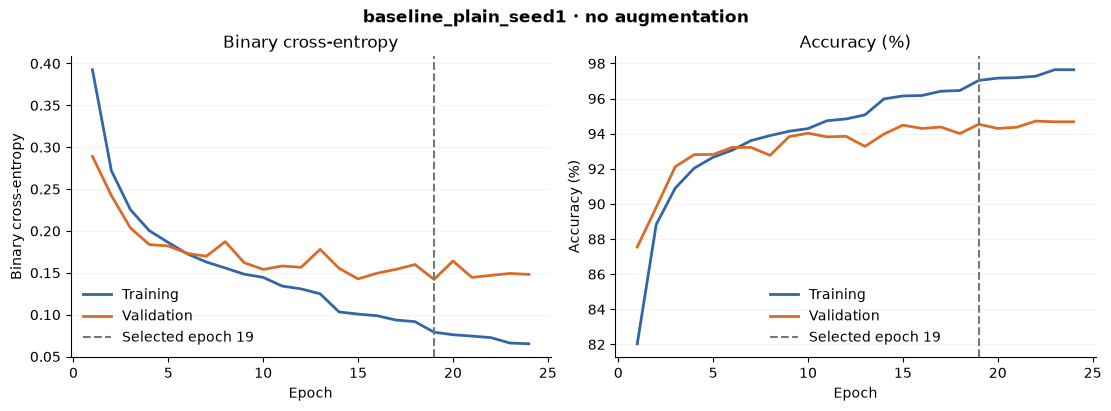

In [16]:
learning_fig = None
if history:
    epochs = [int(row["epoch"]) for row in history]
    learning_fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, metric, scale, title in zip(
        axes, ["loss", "accuracy"], [1, 100], ["Binary cross-entropy", "Accuracy (%)"]
    ):
        ax.plot(
            epochs,
            [float(row[f"train_{metric}"]) * scale for row in history],
            label="Training",
            color="#3465a4",
            lw=2,
        )
        ax.plot(
            epochs,
            [float(row[f"val_{metric}"]) * scale for row in history],
            label="Validation",
            color="#d96b27",
            lw=2,
        )
        ax.axvline(
            selected_epoch,
            color="#777777",
            ls="--",
            label=f"Selected epoch {selected_epoch}",
        )
        ax.set(xlabel="Epoch", ylabel=title, title=title)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.15)
        ax.legend(frameon=False)
    learning_fig.suptitle(f"{RUN_NAME} · no augmentation", fontweight="bold")
    plt.show()
else:
    print("Training history will appear after this run completes.")


## 8. Load the selected model for analysis

For the completed baseline, the trained weights are included **inside this notebook** and can be loaded on a CPU. No retraining, dataset download, sibling `.py` file, or separate model file is required. If a local full run is present, its selected `best.pt` is used. New named runs use their own selected checkpoints; they never silently fall back to the bundled baseline.

The loaded `model` is ready for later analysis. Inputs must be `[batch, 3, 32, 32]` RGB float tensors scaled to `[0,1]` on `device`. `torch.sigmoid(model(inputs))` gives P(REAL). Full optimizer and recovery states stay in local training checkpoints; the bundled weights are for inference.

In [17]:
# Load the selected checkpoint, falling back to the trained weights stored inside this notebook.
checkpoint = None
model = None
checkpoint_path = RUN_DIR / "best.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    checkpoint_source = checkpoint_path.relative_to(ROOT).as_posix()
elif MODEL_PATH.exists():
    exported_summary = read_json(RESULTS_DIR / "summary.json")
    assert file_sha256(MODEL_PATH) == exported_summary["model_sha256"]
    checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
    checkpoint_source = MODEL_PATH.relative_to(ROOT).as_posix()
elif RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
    raw_weights = embedded_bytes(f"models/{EMBEDDED_RUN}.pt")
    assert (
        hashlib.sha256(raw_weights).hexdigest()
        == read_result("summary.json")["model_sha256"]
    )
    checkpoint = torch.load(BytesIO(raw_weights), map_location="cpu", weights_only=True)
    checkpoint_source = "the weights bundled inside this notebook"

if checkpoint is not None:
    model = BaselineCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    assert checkpoint["epoch"] == selected_epoch
    print(f"Loaded epoch {checkpoint['epoch']} from {checkpoint_source}")
    print("Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.")
else:
    print("No selected checkpoint exists for this named run. Finish training first.")


Loaded epoch 19 from the weights bundled inside this notebook
Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.


## 9. Final test evaluation

The threshold is fixed at 0.5. Enable `EVALUATE_TEST` only after training and model selection are complete. If test results already exist, this notebook reads them instead of evaluating again. Test metrics are not used to select the checkpoint or change hyperparameters.

Both the official 20,000-image test set and its 19,962 unique images are reported. In `review` mode the following numbers come from the saved evaluation; they are not a newly computed test score.

The table below will put validation, the full official test set, and the test set with repeated copies counted only once side by side. Alongside accuracy, we'll compare loss, ROC-AUC, the proportion of fake images detected, and the proportion of real images incorrectly flagged as fake. The last two columns are especially useful for understanding what an error means for each class. Comparing the two test rows also lets us see how much repeated images affect the reported scores, without selecting a model or threshold based on those results.

In [18]:
# Display saved test results in review mode; only the explicit evaluation option can calculate them again.
test_report = read_result("test_metrics.json")
if EVALUATE_TEST and test_report is None:
    evaluate_model(RUN_DIR, data_dir=DATA_DIR, device=DEVICE)
    test_report = read_result("test_metrics.json")
elif EVALUATE_TEST:
    print("Existing test evaluation found; reusing it.")

if test_report:
    rows = []
    for label, metrics in (
        ("Validation", run_summary["validation"]),
        ("Official test", test_report["official_test"]),
        ("Unique test", test_report["unique_test"]),
    ):
        rows.append(
            [
                label,
                f"{metrics['n']:,}",
                f"{metrics['accuracy']:.2%}",
                f"{metrics['loss']:.4f}",
                f"{metrics['roc_auc_fake']:.4f}",
                f"{metrics['fake_detection_rate']:.2%}",
                f"{metrics['real_flagged_fake_rate']:.2%}",
            ]
        )
    show_table(
        [
            "Split",
            "Images",
            "Accuracy",
            "BCE",
            "ROC-AUC (fake)",
            "Fake detected",
            "Real flagged fake",
        ],
        rows,
    )
    print("Selected epoch:", test_report["selected_epoch"])
else:
    print(
        "No test evaluation for this run. Finish model selection before enabling EVALUATE_TEST."
    )


| Split | Images | Accuracy | BCE | ROC-AUC (fake) | Fake detected | Real flagged fake |
| --- | --- | --- | --- | --- | --- | --- |
| Validation | 10,000 | 94.54% | 0.1421 | 0.9882 | 94.60% | 5.52% |
| Official test | 20,000 | 94.29% | 0.1501 | 0.9871 | 94.18% | 5.60% |
| Unique test | 19,962 | 94.29% | 0.1500 | 0.9871 | 94.19% | 5.60% |

Selected epoch: 19


### Where the test errors occur

Overall accuracy combines two different kinds of mistake: accepting a fake image as real and flagging a real image as fake. We'll separate them with a confusion matrix using the saved official-test counts from the fixed 0.5 threshold. Rows show the true labels and columns show the predicted labels, so the diagonal cells contain correct classifications. The top-right cell counts fake images that passed as real, and the bottom-left cell counts real images incorrectly flagged as fake. The printed numbers are image counts, with darker shading representing larger counts. Reading the off-diagonal cells will help us see which type of error is more common in this balanced test set. This displays the existing evaluation; it does not run a new test or change the threshold.

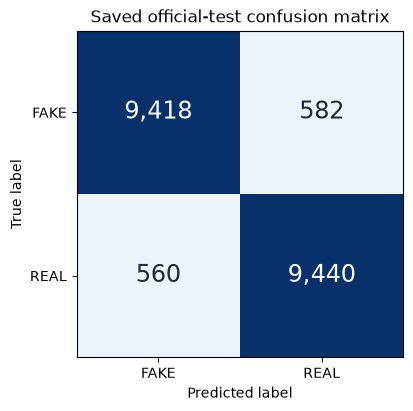

In [19]:
if test_report:
    cm = np.asarray(test_report["official_test"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for (row, col), value in np.ndenumerate(cm):
        ax.text(
            col,
            row,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=17,
            color="white" if value > cm.max() / 2 else "#1f2937",
        )
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["FAKE", "REAL"],
        yticklabels=["FAKE", "REAL"],
        xlabel="Predicted label",
        ylabel="True label",
        title="Saved official-test confusion matrix",
    )
    plt.show()


## 10. Share one notebook; keep recovery checkpoints locally

**Only this `.ipynb` needs to be committed or downloaded for the completed baseline.** It includes the implementation, selected model weights, numerical results, and static figures. A teammate installs the packages, leaves `MODE = "review"`, and runs the notebook. Saved outputs can be read on GitHub without running anything. The phase notebooks carry their own copies of the saved validation data they need.

New training still saves `best.pt`, `last.pt`, and one full checkpoint per epoch under `runs/<RUN_NAME>/`. A notebook alone cannot resume an interrupted run without that run's optimizer and random-state checkpoints. If needed, enable `EXPORT_RUN` below to create a **local** archive of a completed, evaluated run for team storage. This does not publish or commit files. The bundled baseline remains fixed when you train another named run.

Dataset downloads, caches, optional exported figures, and checkpoints are runtime files, not additional required repository files. Commit only the notebook for this workflow.

In [20]:
if EXPORT_RUN:
    if not (RUN_DIR / "test_metrics.json").exists():
        raise RuntimeError(
            "A completed, evaluated local run is required for a full recovery archive."
        )
    archive_path = ROOT / "artifacts" / f"{RUN_NAME}.tar.gz"
    if archive_path.exists():
        print("Keeping the existing archive:", archive_path.relative_to(ROOT))
    else:
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        temporary_archive = archive_path.with_suffix(".tmp")
        with tarfile.open(temporary_archive, "w:gz") as handle:
            handle.add(RUN_DIR, arcname=RUN_NAME)
        temporary_archive.replace(archive_path)
        archive_path.with_suffix(archive_path.suffix + ".sha256").write_text(
            f"{file_sha256(archive_path)}  {archive_path.name}\n"
        )
        print("Saved local recovery archive:", archive_path.relative_to(ROOT))
else:
    print(
        "Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled."
    )
print("Full recovery checkpoints are generated locally only when training is enabled.")


Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled.
Full recovery checkpoints are generated locally only when training is enabled.


## 11. What we learned from training the baseline

The small CNN gives us a useful reference for the model-behaviour project. It was trained from scratch on native 32×32 images, without random augmentation, and completed **24 epochs in about 2 minutes 21 seconds** on this machine. Validation loss selected **epoch 19**, rather than the final epoch. The selected model reached **94.54% validation accuracy** and **94.29% accuracy on the 20,000-image official test set**. These clean results show that there is enough information at this resolution for this network to separate the two CIFAKE classes. They do not, by themselves, tell us which visual cues the model relies on or whether those cues survive changes to an image.

**The questions this result leaves open are answered in the phase notebooks.** Phase I (`phase1/`) treats the trained model as a black box and asks how its outputs move when images change: JPEG compression, blur, resizing, noise, sharpening and colour edits, broken down by object class, image properties and agreement with ResNet18. Phase II (`phase2/01_cnn_internals.ipynb`) opens the model with Grad-CAM, exact neuron contributions, occlusion, filter views and channel removal.

The saved analysis includes checks of data integrity, score reconstruction and explanation calculations. Those checks support the correctness of the implementation; they do not make an attribution method a complete explanation or turn this single seeded experiment into a general robustness claim.